
## Задача - Предсказать поведение клиентов (отток) с целью разработки программ удержания клиентов (датасет от kaggle)


Набор данных (каждая строка представляет клиента) включает информацию о:

    Клиентах, которые ушли в течение последнего месяца – колонка Churn
    
    Услуги, на которые подписан каждый клиент - телефон (PhoneService), несколько линий (MultipleLines), интернет (InternetService), онлайн-безопасность (OnlineSecurity), онлайн-резервное копирование (OnlineBackup), защита устройств (DeviceProtection), техническая поддержка (TechSupport), потоковое телевидение (StreamingTV), фильмы (StreamingMovies)
    
    Информация об учетной записи клиента - продолжительность сотрудничества (tenure), контракт (Contract), способ оплаты (PaymentMethod), способ выставления счетов (PaperlessBilling), ежемесячные платежи (MonthlyCharges) и общие расходы (TotalCharges)
    
    Соц-демографическая информация о клиентах – пол (gender), возрастной диапазон (SeniorCitizen), есть ли партнеры (Partner) и иждивенцы (Dependents)


In [63]:
# Качаем и распаковываем датасет
!curl -L -o telco-customer-churn.zip https://www.kaggle.com/api/v1/datasets/download/blastchar/telco-customer-churn
!tar -xf telco-customer-churn.zip
!unzip telco-customer-churn.zip

  % Total    % Received % Xferd  Average Speed  Time    Time    Time   Current
                                 Dload  Upload  Total   Spent   Left   Speed

  0      0   0      0   0      0      0      0                              0
  0      0   0      0   0      0      0      0                              0
  0      0   0      0   0      0      0      0                              0

  0      0   0      0   0      0      0      0                              0
100 171.6k 100 171.6k   0      0 173.4k      0                              0
100 171.6k 100 171.6k   0      0 173.4k      0                              0
100 171.6k 100 171.6k   0      0 173.4k      0                              0
"unzip" ­Ґ пў«пҐвбп ў­гваҐ­­Ґ© Ё«Ё ў­Ґи­Ґ©
Є®¬ ­¤®©, ЁбЇ®«­пҐ¬®© Їа®Ја ¬¬®© Ё«Ё Ї ЄҐв­л¬ д ©«®¬.


для работы кода нужны следующие библиотеки

In [116]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns


from phik import report

from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import make_column_selector as selector
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import TargetEncoder, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.calibration import CalibrationDisplay
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
from sklearn.metrics import auc
from sklearn.metrics import roc_curve
from sklearn.metrics import RocCurveDisplay
from sklearn.metrics import PrecisionRecallDisplay

from sklearn.inspection import permutation_importance

# Загрузка данных

In [65]:
data = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Построение любой модели начинается с подготовки датасета

Посмотрим данные на предмет типов, в данных есть столбец TotalCharges с типом object, его нужно конвертировать в числовой тип, а SeniorCitizen - наоборот, нужно перевести в строковое значение, иначе линейная модель воспримет значения как порядковые. Еще есть айдишники, их нужно удалить


In [66]:
data['TotalCharges'] = data['TotalCharges'].apply(pd.to_numeric, errors="coerce")
data['SeniorCitizen'] = data['SeniorCitizen'].astype('str')
data = data.drop(['customerID'], axis=1)
data.dtypes.to_frame()

,0
gender,str
SeniorCitizen,str
Partner,str
Dependents,str
tenure,int64
PhoneService,str
MultipleLines,str
InternetService,str
OnlineSecurity,str
OnlineBackup,str


Делим датасет на фичи и таргет, т е на X-сы и y (то что нужно предсказать)

In [67]:
X_ = data.drop(['Churn'], axis=1)
y_ = data['Churn'].replace({"Yes": 1, "No": 0})
y_ = y_.astype(int)

мы не можем готовить датасет на всех данных, так как это будет нечестным подглядываем в данные для теста, поэтому до обработки данных нужно отделить тестовые данные от тренировочных 

In [68]:
X_train, X_test, y_train, y_test = train_test_split(
    X_,
    y_,
    test_size=0.15,
    random_state=211 # <--- отвечает за случайность разделения
)

In [69]:
X_train.shape, X_test.shape

((5986, 19), (1057, 19))

# Подготовка датасета

Подготовка данных обычно происходит по следующим этапам:

I. Очистка данных
 - Фильтрация столбцов
 - Фильтрация фичей (вещественные)
 - Фильтрация фичей (категориальные)
 - Фильтрация наблюдений

II. Работа с пропусками
 - Заполнение средним/медианой/модой
 - Заполнение категориальной фичи новой категорией

III. Кодировка категориальных признаков
 - One-hot encoding
 - Счетчики

IV. Масштабирование
 - MinMaxScaler
 - StandardScaler

## итак, I. Очистка данных

фильтруем столбцы с пропусками - столбцы, в которых пропусков будет больше 80%, точно мусорные фичи


In [70]:
(X_train.isna().sum() / X_train.shape[0]).sort_values().to_frame()

,0
gender,0.000000
SeniorCitizen,0.000000
Partner,0.000000
Dependents,0.000000
tenure,0.000000
PhoneService,0.000000
MultipleLines,0.000000
InternetService,0.000000
OnlineSecurity,0.000000
OnlineBackup,0.000000


также надо изучить, сколько пропусков в наблюдениях - если больше 50% в строке, тоже лучше удалить такие строки

In [71]:
(X_train.isna().sum(axis=1) / X_train.shape[1]>0.5).sum()

np.int64(0)

проверяем числовые фичи на корреляцию - высокий уровень корреляции между колонками нежелателен, будем удалять корреляции выше 0.8

In [72]:
X_numerics_columns = X_train.select_dtypes(include=np.number).columns
X_numerics_columns = [col for col in X_numerics_columns if col in ['tenure', 'MonthlyCharges', 'TotalCharges']]
X_[X_numerics_columns].corr()

,tenure,MonthlyCharges,TotalCharges
tenure,1.00000,0.247900,0.825880
MonthlyCharges,0.24790,1.000000,0.651065
TotalCharges,0.82588,0.651065,1.000000


есть связь между продолжительностью жизни клиента и общими расходами, удалим общие расходы, чтобы избежать мультиколлинеарности

Чтобы каждый раз не чистить - обрабатывать данные, лучше подготовить единый пайнплайн обработки и начать можно с кастомного трансформера для фильтрации столбцов и строк, коррелирующих фичей 

In [73]:
def correlation(dataset, threshold):
        col_corr = set()
        corr_matrix = dataset.corr().abs()
        cols_to_del = []
        for i in range(len(corr_matrix.columns)):
            for j in range(i):
                if (corr_matrix.iloc[i, j] >= threshold) and (corr_matrix.columns[j] not in col_corr):
                    colname = corr_matrix.columns[i] 
                    col_corr.add(colname)
                    if colname in dataset.columns:
                        cols_to_del.append(colname)

        return cols_to_del

class CustomTransformer(BaseEstimator, TransformerMixin):
    def __init__(
        self,
        #keys_features=['customerID'],
        nan_column=0.8,
        nan_row=0.5,
        corr_threshold=0.8

    ):

        self.nan_column = nan_column
        self.nan_row = nan_row
        self.corr_threshold = corr_threshold
        #self.keys_features = keys_features

    def fit(self, X, y):

        if not hasattr(X, "iloc"):
            raise ValueError(
                "CustomTransformer can only be applied to pandas dataframes in X argument"
            )

        # Застрахуемся от inplace изменений
        X_copy= X.copy()
        y_copy = y.copy()


        # Найдем фичи, в которых много пропусков
        nan_share_c = X_copy.isna().sum() / X_copy.shape[0]
        self.nan_features_c = nan_share_c[nan_share_c > self.nan_column].index.tolist()

        # Найдем наблюдения, в которых много пропусков

        nan_share_r = X_copy.isna().sum(axis=1) / X_copy.shape[1]
        self.nan_features_r = nan_share_r[nan_share_r > self.nan_row].index.tolist()

        # Найдем коррелирующие фичи
        self.corr_cols = correlation(X_copy.select_dtypes(include='number'), self.corr_threshold)

        return self

    def transform(self, X):
        if not hasattr(X, "iloc"):
            raise ValueError(
                "CustomTransformer can only be applied to pandas dataframes in X argument"
            )
        X_copy= X.copy()


        # Уберем nan, коррелирующие фичи. Также стоит фильтровать те категориальные фичи, которые уникальны (или почти) для каждого наблюдения
        X_copy.drop(self.nan_features_c, axis=1, inplace=True)
        X_copy.drop(self.nan_features_r, axis=0, inplace=True)
        X_copy.drop(self.corr_cols, axis=1, inplace=True)

        # Уберем также фичи-ключи
       # X_copy.drop(self.keys_features, axis=1, inplace=True)

        return X_copy

    def inverse_transform(self):
        pass

## Cледующий этап это II. Работа с пропусками

У нас были пропуски только в одном столбце, но на предыдущем этапе, мы выявили корреляцию и удалили данный столбец

## Следующий этап это III. Кодировка категориальных признаков

Чтобы оцифровываем категориальные, смотрим какую стратегию применить One-hot encoding или счетчики

In [74]:
X_filtered_categorical_columns = X_train.select_dtypes(exclude=np.number).columns
X_[X_filtered_categorical_columns].nunique()

gender              2
SeniorCitizen       2
Partner             2
Dependents          2
PhoneService        2
MultipleLines       3
InternetService     3
OnlineSecurity      3
OnlineBackup        3
DeviceProtection    3
TechSupport         3
StreamingTV         3
StreamingMovies     3
Contract            3
PaperlessBilling    2
PaymentMethod       4
dtype: int64

Так как значений мало, можно применить One-hot encoding напишем кастомный selector, который будет выбирать колонки для OHE и трансформер. 

При написании кастомного трансформера нужно помнить, что у нас есть мультиколлинеарность, поэтому после оцифровки нам нужно удалять определенные столбцы, а не по умолчанию первые

В блоке EDA мы нашли мультиколлинеарность и определили какие столбцы нам нужно удалить

Шаг 1. Убираем дубликаты «Нет интернета»

• OnlineSecurity_No internet service 
• OnlineBackup_No internet service 
• DeviceProtection_No internet service 
• TechSupport_No internet service 
• StreamingTV_No internet service 
• StreamingMovies_No internet service

Шаг 2. Удаляем MultipleLines_No phone service - этот дубликат PhoneService_No, но тогда у нас остались MultipleLines_No и MultipleLines_Yes - оставим только MultipleLines_Yes

Шаг 3. Удалим также InternetService_No (если DSL и Fiber равны 0, модель сама поймет, что интернета нет)

Шаг 4. Для доп услуг интернета (после удаления категории No internet service на Шаге 1) у нас остались пары _No и _Yes. Удаляем все _No:
• OnlineSecurity_No 
• OnlineBackup_No 
• DeviceProtection_No
• TechSupport_No
• StreamingTV_No
• StreamingMovies_No 

В остальных категориальных убираем по умолчанию первое 

In [75]:
class CustomOHETransformer(BaseEstimator, TransformerMixin):
    def __init__(self, ohe_limiter=5):
        self.ohe_limiter = ohe_limiter
        self.ohe_cols_ = []
        self.all_dummy_columns_ = []
        self.final_cols_to_drop_ = []

        # Оставляем здесь только те фичи, которые не попали в кейсы 1 и 2
        self.specific_drops = {
            'PhoneService': 'PhoneService_No',
            'InternetService': 'InternetService_No'
        }

    def fit(self, X, y=None):
        # 1. Фиксируем список неколичественных колонок
        df_obj = X.select_dtypes(exclude='number')
        counter_ = df_obj.nunique()
        self.ohe_cols_ = counter_[counter_ <= self.ohe_limiter].index.tolist()

        self.all_dummy_columns_ = []
        self.final_cols_to_drop_ = []

        # Список вложенных интернет-услуг, где нужно оставить ТОЛЬКО флаг _Yes
        internet_services = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                             'TechSupport', 'StreamingTV', 'StreamingMovies']

        # 2. Фиксируем структуру dummy-колонок и определяем, что удалять
        for col in self.ohe_cols_:
            X_dummy = pd.get_dummies(X[[col]], columns=[col], dtype=int)
            dummy_features = X_dummy.columns.tolist()
            self.all_dummy_columns_.extend(dummy_features)

            # Кейс 1: Вложенные интернет-услуги (удаляем и No, и No internet service)
            if col in internet_services:
                for f in dummy_features:
                    if f.endswith('_No') or 'No internet service' in f:
                        self.final_cols_to_drop_.append(f)

            # Кейс 2: Мультилинии (удаляем и No, и No phone service)
            elif col == 'MultipleLines':
                for f in dummy_features:
                    if f.endswith('_No') or 'No phone service' in f:
                        self.final_cols_to_drop_.append(f)

            # Кейс 3: Остальные специфичные дропы (например, PhoneService, InternetService)
            elif col in self.specific_drops:
                target_drop = self.specific_drops[col]
                if target_drop in dummy_features:
                    self.final_cols_to_drop_.append(target_drop)

            # Кейс 4: Стандартный OHE-дроп (первая колонка по алфавиту)
            else:
                dummy_features.sort()
                self.final_cols_to_drop_.append(dummy_features[0])

        return self

    def transform(self, X):
        X_res = X.copy()
        all_dummies_df = []

        # Идем строго по тем колонкам, которые запомнили во fit
        for col in self.ohe_cols_:
            X_dummy = pd.get_dummies(X_res[[col]], columns=[col], dtype=int)
            all_dummies_df.append(X_dummy)

        if all_dummies_df:
            X_all_dummies = pd.concat(all_dummies_df, axis=1)

            # Принудительно создаем структуру трейна (заполняем нулями отсутствующие категории)
            X_all_dummies = X_all_dummies.reindex(columns=self.all_dummy_columns_, fill_value=0)

            # Удаляем базовые избыточные колонки, собранные по новым правилам во fit
            X_all_dummies = X_all_dummies.drop(columns=self.final_cols_to_drop_, errors='ignore')

            # Джойним к исходному датасету и удаляем старые текстовые фичи
            X_res = pd.concat([X_res, X_all_dummies], axis=1)
            X_res = X_res.drop(columns=self.ohe_cols_)

        return X_res

## Остается заключительный этап - масштабирование, напишем его сразу в пайплане

In [76]:
final_process_pipe = Pipeline(
    [
        ("custom_transformer", CustomTransformer()),
        ('custom_ohe', CustomOHETransformer(ohe_limiter=5)), 
        ('scaler_selective', make_column_transformer(
            (StandardScaler(), ['tenure', 'MonthlyCharges'] 
),
            remainder='passthrough',
            verbose_feature_names_out=False
        ).set_output(transform='pandas'))
    ]
)

final_process_pipe.fit_transform(X_train, y_train).head()

,tenure,MonthlyCharges,gender_Male,SeniorCitizen_1,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_Yes,InternetService_DSL,InternetService_Fiber optic,...,DeviceProtection_Yes,TechSupport_Yes,StreamingTV_Yes,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
2991,0.184722,0.838025,0,1,1,0,1,0,0,1,...,1,1,1,0,0,0,0,0,1,0
5187,0.347542,1.315707,0,1,0,0,1,1,0,1,...,1,0,1,1,0,0,1,0,1,0
4683,-0.344441,0.974032,1,0,0,0,1,1,0,1,...,0,0,1,1,0,0,1,0,1,0
4347,0.713885,1.176383,0,0,0,0,1,0,0,1,...,0,1,1,1,0,1,1,0,0,1
6163,-0.547965,0.808170,0,0,1,0,1,1,0,1,...,0,0,0,1,0,0,1,0,1,0


данные для модели готовы!

# III. Выбор модели & IV. Функция ошибки и оптимизация


Давайте начнем с построения линейных моделей классификации, то есть построим некоторую разделяющую гиперплоскость в пространстве признаков.

Выбор функции ошибок и оптимизации -  определяется стратегией сглаживания Loss'а на отступах: SVM или LogReg.
Также в линейных классификаторах в sklearn иногда доступна настройка оптимизации.

В sklearn представлены, как минимум, следующие классы, позволяющие реализовать SVM или LogReg:

    LogisticRegression - напрямую оптимизируется logloss, но можно выбирать различные solver'ы (lbfgs, liblinear, newton-cg, newton-cholesky, sag, saga). Также доступна elastic-net регуляризация (комбинация l1 и l2) и некоторые другие уникальные гиперпараметры.
    LinearSVC - SVM, который обучается напрямую через классический (полный) градиент


In [77]:
# Инициализируем пайплайны с обеими моделями
lr_pipe = Pipeline(
    [
        ('all_preprocess', final_process_pipe),
        ('simple_model', LogisticRegression())
    ]
)

svm_pipe = Pipeline(
    [
        ('all_preprocess', final_process_pipe),
        ('simple_model', LinearSVC())
    ]
)

In [78]:
# Проверим как работает LR_PIPE
# Доступен как метод .predict, так и .predict_proba для оценки вероятностей
# Также доступно "расстояние" каждого объекта до разделяющей гиперплоскости
# Для этого используется decision function

lr_pipe.fit(X_train, y_train)

sample = X_train.head()

lr_pipe.predict_proba(sample), \
lr_pipe.predict(sample), \
lr_pipe.decision_function(sample)

(array([[0.66106062, 0.33893938],
        [0.40646816, 0.59353184],
        [0.30417309, 0.69582691],
        [0.92129517, 0.07870483],
        [0.32773516, 0.67226484]]),
 array([0, 1, 1, 0, 1]),
 array([-0.66802428,  0.37858526,  0.82750403, -2.46007595,  0.71844655]))

In [79]:
# Проверим как работает SVM_PIPE
# Здесь уже оценка вероятности не доступна!

svm_pipe.fit(X_train, y_train)

svm_pipe.predict(sample), \
svm_pipe.decision_function(sample)

(array([0, 1, 1, 0, 1]),
 array([-0.2494215 ,  0.12049416,  0.31261139, -0.68228523,  0.26710299]))

Какие метрики будем оптимизировать?

Давайте оптимизировать recall - ловить как можно больше "отточников" и предлагать более льготные условия утекающим клиентам. Но, более льготные условия снижают прибыль компании, поэтому нужно зафиксировать точность (precision) модели, она должна быть не меньше 70%.
В задаче оттока такая стратегия применяется, когда удерживающие мероприятия (бонусы, скидки, звонки операторов) обходятся компании дорого. Высокий Precision гарантирует, что мы не будем тратить бюджет на удержание лояльных клиентов (минимум «ложных тревог»).

Таким образом, можно:

    Оптимизировать F-метрику или PR-AUC, потому что они учитывают сразу и precision, и recall, и надеяться, что у лучшей модели действительно будет такой порог отсечения t, что будет доступно precision >70%
    Замерять одновременно и precision, и recall, оставить только те модели, у которых precision >70% и выбрать среди них лучшую по метрике recall

второй вариант выглядит интереснее

но, есть проблема - по дефолту, классификаторы из sklearn дают положительный прогноз для объектов с t > 0.5.
Для LogReg t есть отсечка для оценки вероятности через сигмоиду.
В случае, когда мы оптимизируем метрики, не зависящие от порога t, он не является для нас гиперпараметром.
В остальных случаях (таких как с accuracy, precision, recall) - это гиперпараметр модели.
Необходимо модернизировать наши estimator'ы таким образом, чтобы порог отсечения t был гиперпараметром.


In [80]:
# Передадим сюда сразу pipe с обработкой данных

class LogRegClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, threshold=0.5, subestimator=None):
        self.threshold = threshold
        self.subestimator = subestimator

    def fit(self, X, y):
        # Копируем входные данные
        X, y = X.copy(), y.copy()

        # Если subestimator не передан, или чтобы избежать затирания памяти,
        # клонируем базовый пайплайн. Это изолирует каждый фолд в GridSearchCV!
        if self.subestimator is None:
            self.subestimator_ = clone(lr_pipe)
        else:
            self.subestimator_ = clone(self.subestimator)

        # Обучаем изолированную копию пайплайна
        self.subestimator_.fit(X, y)

        # Сохраняем атрибуты 
        self.classes_ = self.subestimator_.classes_

        # Достаем коэффициенты из обученной копии
        self.coef_ = self.subestimator_["simple_model"].coef_
        self.intercept_ = self.subestimator_["simple_model"].intercept_

        return self

    def predict(self, X):
        # Используем внутренний обученный subestimator_ и учитываем порог
        probas = self.subestimator_.predict_proba(X)[:, 1] > self.threshold
        return probas.astype(int)

    def predict_proba(self, X):
        return self.subestimator_.predict_proba(X)

lrc_modified = LogRegClassifier(subestimator=lr_pipe)
lrc_modified.fit(X_train, y_train)
lrc_modified.predict(X_train)

array([0, 1, 1, ..., 0, 0, 0], shape=(5986,))

С SVM будет немного сложнее - В реализации sklearn не встроена калибровка результатов модели SVM в вероятности, результаты никак не ранжируются в отрезок от 0 до 1. \
Тем не менее, уверенность классификатора в каждом объекте можно ранжировать через метод .decision_function (выровняет выходы в отрезок 0-1, т е появятся такие же свойства как у калибровочной кривой  \
В начале применим к ранжированному списку калибровку, после чего поступим как и с LogReg!

In [81]:
# Простой пример работы калибровки
calibrated = CalibratedClassifierCV(svm_pipe, method='isotonic', cv=3)
calibrated.fit(X_train, y_train)
calibrated.predict_proba(sample)

array([[0.68310626, 0.31689374],
       [0.42777778, 0.57222222],
       [0.30822517, 0.69177483],
       [0.85333333, 0.14666667],
       [0.31646547, 0.68353453]])

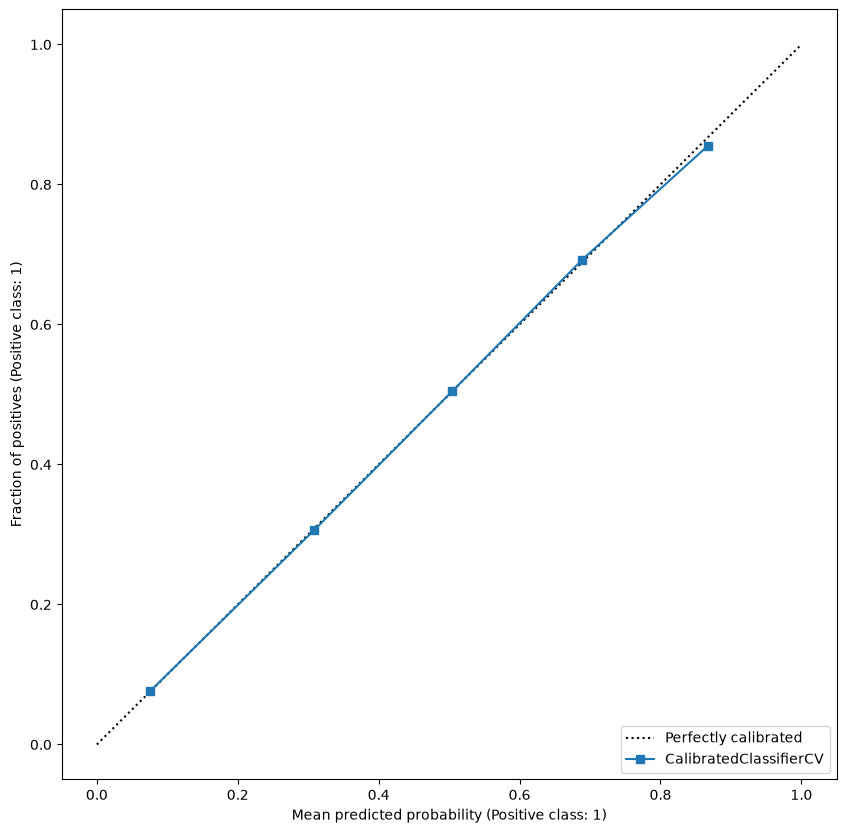

In [82]:
# Построение калибровочной кривой
# Кажется, она работает нормально

fig, ax = plt.subplots(figsize=(10, 10))
CalibrationDisplay.from_estimator(calibrated, X_train, y_train, ax=ax)

In [85]:
# Теперь напишем класс для SVM с threshold'ом как гиперпараметром
class SVMClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, threshold=0.5, subestimator=None, calibration=None):
        self.threshold = threshold
        self.subestimator = subestimator
        self.calibration = calibration

    def fit(self, X, y):
        # 1. Жестко копируем входные данные
        X, y = X.copy(), y.copy()

        # 2. Изолируем базовый пайплайн (svm_pipe)
        if self.subestimator is None:
            # Делаем копию глобального svm_pipe, если ничего не передали
            base_estimator = clone(svm_pipe)
        else:
            base_estimator = clone(self.subestimator)

        # 3. Изолируем калибратор
        if self.calibration is None:
            # Создаем чистый дефолтный калибратор
            calibrator_template = CalibratedClassifierCV(method='isotonic', cv=3)
        else:
            # Клонируем переданный калибратор, чтобы не портить внешние объекты
            calibrator_template = clone(self.calibration)

        # Настраиваем параметры на склонированном шаблоне
        calibrator_template.set_params(estimator=base_estimator, method='isotonic', cv=3)
        
        # Записываем в финальный обученный атрибут (строго с суффиксом _)
        self.calibration_ = calibrator_template

        # 4. Обучаем 
        self.calibration_.fit(X, y)

        # 5. Сохраняем обязательные sklearn-атрибуты из обученной копии
        self.classes_ = self.calibration_.classes_

        return self

    def predict(self, X):
        # Используем внутренний изолированный и обученный calibration_
        probas = self.calibration_.predict_proba(X)[:, 1] > self.threshold
        return probas.astype(int)

    def predict_proba(self, X):
        # Используем внутренний изолированный и обученный calibration_
        return self.calibration_.predict_proba(X)

# Пример инициализации и запуска (теперь под капотом всё чисто)
svmc_modified = SVMClassifier(threshold=0.3, subestimator=svm_pipe)
svmc_modified.fit(X_train, y_train)
preds = svmc_modified.predict(X_train)


Валидация и поиск лучших гиперпараметров по сетке

GridSearchCV умеет "влоб" находить лучшие гиперпараметры по какой-то конкретной метрике. В нашем случае - это recall с ограничением на precision. Звучит достаточно кастомно, придется писать отдельную функцию, которая поможет GridSearchCV действительно определить лучшую модель!


In [86]:
# Функция для определения стратегии выбора лучших гиперпараметров
# Учитывая и желание максимизировать recall, и ограничение на precision!

# 1. функция вывода 
def print_dataframe(filtered_cv_results):
    """Pretty print for filtered dataframe"""
    if filtered_cv_results.empty:
        print("Нет моделей, соответствующих условиям.\n")
        return
        
    for mean_precision, std_precision, mean_recall, std_recall, params in zip(
        filtered_cv_results["mean_test_precision"],
        filtered_cv_results["std_test_precision"],
        filtered_cv_results["mean_test_recall"],
        filtered_cv_results["std_test_recall"],
        filtered_cv_results["params"],
    ):
        print(
            f"precision: {mean_precision:0.3f} (±{std_precision:0.03f}),"
            f" recall: {mean_recall:0.3f} (±{std_recall:0.03f}),"
            f" for {params}"
        )
    print()


# 2. Сама стратегия отбора (выводит ТОЛЬКО блок 2 и блок 3)
def refit_strategy(cv_results):
    # Порог отсечения по точности
    precision_threshold = 0.70

    # Переводим результаты в DataFrame
    cv_results_ = pd.DataFrame(cv_results)

    # Убираем все модели, не прошедшие порог 
    high_precision_cv_results = cv_results_[
        cv_results_["mean_test_precision"] > precision_threshold
    ]

    print(f"--- Модели с precision > {precision_threshold} ---")
    print_dataframe(high_precision_cv_results)

    # Защита от пустой таблицы (если ни одна модель не набрала precision > 0.70)
    if high_precision_cv_results.empty:
        print("ВНИМАНИЕ: Ни одна модель не прошла порог Precision! Берем модель с максимальным Precision.")
        return cv_results_["mean_test_precision"].idxmax()

    # Оставляем нужные колонки для удобства
    high_precision_cv_results = high_precision_cv_results[
        [
            "mean_score_time",
            "mean_test_recall",
            "std_test_recall",
            "mean_test_precision",
            "std_test_precision",
            "rank_test_recall",
            "rank_test_precision",
            "params",
        ]
    ]

    # Выбираем лучшую модель среди найденных по Recall ---
    best_recall = high_precision_cv_results["mean_test_recall"].max()

    high_recall_cv_results = high_precision_cv_results[
        high_precision_cv_results["mean_test_recall"] == best_recall
    ]
    
    print("--- Лучшая среди них (максимальный Recall) ---")
    print_dataframe(high_recall_cv_results)

    # Выбор индекса модели (если их несколько — берем самую быструю)
    fastest_top_recall_high_precision_index = high_recall_cv_results[
        "mean_score_time"
    ].idxmin()

    return fastest_top_recall_high_precision_index


In [87]:
scores = ('precision', 'recall')

Давайте обучать модель на кросс-валидации: поделим данные для обучения на 4 части и будем брать 3 части в обучение, а одну в валидацию данных и так 4 раза, меняя валидационную часть

In [88]:
# Зафиксируем стратегию валидации в переменную splitter для train части
splitter = KFold(
    n_splits=4,        # Сколько частей будем обучать, т е 3 части обучаем и валидируем на четвертой
    shuffle=True,      # Перемешаем данные
    random_state=100   # Случайное число
)

давайте вначале посмотрим, нет ли мультиколлинеарность с помощью L1-регуляризация (Lasso)

In [89]:
# Сделаем сетку из параметров для GridSearch'а
# для L1-регуляризация (Lasso) и силой регуляризации 1

lr_grid_lasso_1 = {
    'subestimator__simple_model__C' : [ 0.1, 1.0],                # Общая сила регуляризации (чем меньше, тем сильнее штраф)
    'subestimator__simple_model__fit_intercept': [True, False],   # Добавлять ли свободный коэффициент к уравнению гиперплоскости
    'subestimator__simple_model__penalty': ['l1'],                # Тип регуляризации
    'subestimator__simple_model__solver': ['liblinear', 'saga'],  # Алгоритм оптимизации
    'threshold': [0.4, 0.5, 0.6, 0.7]                             # Порог отсечения вероятности
}

In [90]:
print("Поиск лучших параметров Логистической регрессии L1-регуляризация (Lasso) при силе регуляризации равной 1:")
search_lr_Lasso_1 = GridSearchCV(lrc_modified, lr_grid_lasso_1,
                         cv=splitter, scoring=scores,
                         refit=refit_strategy)

result = search_lr_Lasso_1.fit(X_train, y_train)

Поиск лучших параметров Логистической регрессии L1-регуляризация (Lasso) при силе регуляризации равной 1:
--- Модели с precision > 0.7 ---
precision: 0.712 (±0.052), recall: 0.368 (±0.010), for {'subestimator__simple_model__C': 0.1, 'subestimator__simple_model__fit_intercept': True, 'subestimator__simple_model__penalty': 'l1', 'subestimator__simple_model__solver': 'liblinear', 'threshold': 0.6}
precision: 0.804 (±0.061), recall: 0.174 (±0.027), for {'subestimator__simple_model__C': 0.1, 'subestimator__simple_model__fit_intercept': True, 'subestimator__simple_model__penalty': 'l1', 'subestimator__simple_model__solver': 'liblinear', 'threshold': 0.7}
precision: 0.707 (±0.045), recall: 0.359 (±0.011), for {'subestimator__simple_model__C': 0.1, 'subestimator__simple_model__fit_intercept': True, 'subestimator__simple_model__penalty': 'l1', 'subestimator__simple_model__solver': 'saga', 'threshold': 0.6}
precision: 0.791 (±0.049), recall: 0.180 (±0.027), for {'subestimator__simple_model__C': 

In [91]:
ranged = pd.DataFrame(
    {
        'Beta': search_lr_Lasso_1.best_estimator_.coef_[0],
        'Colname': final_process_pipe.fit_transform(X_train, y_train).columns
    }
)

ranged.loc[-1] = [search_lr_Lasso_1.best_estimator_.intercept_, 'свободный коэффициент']
ranged.sort_values('Beta')

,Beta,Colname
17,-1.353402,Contract_Two year
6,-1.147209,PhoneService_Yes
0,-0.856429,tenure
16,-0.697950,Contract_One year
13,-0.548386,TechSupport_Yes
10,-0.503216,OnlineSecurity_Yes
11,-0.252555,OnlineBackup_Yes
5,-0.216569,Dependents_Yes
12,-0.159886,DeviceProtection_Yes
14,-0.075424,StreamingTV_Yes


Удалим избыточные занулившиеся бинарные признаки и пересчитаем модель

In [92]:
# Функция, которая будет дропать занулившиеся столбцы
def drop_zero_lasso_features(df):
    columns_to_drop = ['StreamingMovies_Yes', 'PaymentMethod_Mailed check', 'InternetService_DSL']
    # errors='ignore' защитит пайплайн от падения, если на тесте вдруг не окажется этих колонок
    return df.drop(columns=columns_to_drop, errors='ignore')

final_process_pipe_new = Pipeline(
    [
        ("custom_transformer", CustomTransformer()),
        ('custom_ohe', CustomOHETransformer(ohe_limiter=5)),
        ('drop_lasso_features', FunctionTransformer(drop_zero_lasso_features)),
        ('scaler_selective', make_column_transformer(
            (StandardScaler(), ['tenure', 'MonthlyCharges']),
            remainder='passthrough',
            verbose_feature_names_out=False
        ).set_output(transform='pandas'))
    ]
)

final_process_pipe_new.fit_transform(X_train, y_train)

,tenure,MonthlyCharges,gender_Male,SeniorCitizen_1,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_Yes,InternetService_Fiber optic,OnlineSecurity_Yes,OnlineBackup_Yes,DeviceProtection_Yes,TechSupport_Yes,StreamingTV_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check
2991,0.184722,0.838025,0,1,1,0,1,0,1,0,0,1,1,1,0,0,0,0,1
5187,0.347542,1.315707,0,1,0,0,1,1,1,0,1,1,0,1,0,0,1,0,1
4683,-0.344441,0.974032,1,0,0,0,1,1,1,0,0,0,0,1,0,0,1,0,1
4347,0.713885,1.176383,0,0,0,0,1,0,1,0,1,0,1,1,0,1,1,0,0
6163,-0.547965,0.808170,0,0,1,0,1,1,1,0,1,0,0,0,0,0,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3844,0.103313,0.703678,0,0,0,0,1,1,0,1,0,1,1,1,1,0,1,1,0
4604,1.324458,1.139893,1,1,0,0,1,0,1,0,1,1,0,1,0,0,1,0,0
1886,1.405867,-0.143875,1,0,1,1,1,0,0,1,0,1,1,0,0,1,1,0,0
7014,0.347542,0.811488,1,0,0,0,1,1,1,0,1,0,0,1,0,0,1,0,1


In [93]:
lr_pipe = Pipeline(
    [
        ('all_preprocess', final_process_pipe_new),
        ('simple_model', LogisticRegression())
    ]
)
svm_pipe = Pipeline(
    [
        ('all_preprocess', final_process_pipe_new),
        ('simple_model', LinearSVC())
    ]
)

In [94]:
# Передаем новый lr_pipe принудительно, чтобы Python не брал старый дефолтный
lrc_modified = LogRegClassifier(subestimator=lr_pipe)

lrc_modified.fit(X_train, y_train)
lrc_modified.predict(X_train)


array([0, 1, 1, ..., 0, 0, 0], shape=(5986,))

In [95]:
svmc_modified = SVMClassifier(subestimator=svm_pipe)

svmc_modified.fit(X_train, y_train)
svmc_modified.predict(X_train)


array([0, 1, 1, ..., 0, 0, 0], shape=(5986,))

перестроим модель без занулившихся бинарных признаков

In [97]:
print("Поиск лучших параметров Логистической регрессии L1-регуляризация (Lasso) при силе регуляризации равной 1:")
search_lr_Lasso_1 = GridSearchCV(lrc_modified, lr_grid_lasso_1,
                         cv=splitter, scoring=scores,
                         refit=refit_strategy)

result = search_lr_Lasso_1.fit(X_train, y_train)

Поиск лучших параметров Логистической регрессии L1-регуляризация (Lasso) при силе регуляризации равной 1:
--- Модели с precision > 0.7 ---
precision: 0.713 (±0.051), recall: 0.369 (±0.011), for {'subestimator__simple_model__C': 0.1, 'subestimator__simple_model__fit_intercept': True, 'subestimator__simple_model__penalty': 'l1', 'subestimator__simple_model__solver': 'liblinear', 'threshold': 0.6}
precision: 0.804 (±0.061), recall: 0.174 (±0.027), for {'subestimator__simple_model__C': 0.1, 'subestimator__simple_model__fit_intercept': True, 'subestimator__simple_model__penalty': 'l1', 'subestimator__simple_model__solver': 'liblinear', 'threshold': 0.7}
precision: 0.707 (±0.044), recall: 0.360 (±0.011), for {'subestimator__simple_model__C': 0.1, 'subestimator__simple_model__fit_intercept': True, 'subestimator__simple_model__penalty': 'l1', 'subestimator__simple_model__solver': 'saga', 'threshold': 0.6}
precision: 0.788 (±0.054), recall: 0.179 (±0.027), for {'subestimator__simple_model__C': 

In [98]:
ranged = pd.DataFrame(
    {
        'Beta': search_lr_Lasso_1.best_estimator_.coef_[0],
        'Colname': final_process_pipe_new.fit_transform(X_train, y_train).columns
    }
)

ranged.loc[-1] = [search_lr_Lasso_1.best_estimator_.intercept_, 'свободный коэффициент']
ranged.sort_values('Beta')

,Beta,Colname
15,-1.353338,Contract_Two year
6,-1.146191,PhoneService_Yes
0,-0.856425,tenure
14,-0.697968,Contract_One year
12,-0.548648,TechSupport_Yes
9,-0.503372,OnlineSecurity_Yes
10,-0.252660,OnlineBackup_Yes
5,-0.216517,Dependents_Yes
11,-0.159983,DeviceProtection_Yes
13,-0.075773,StreamingTV_Yes




метрики до удаления занулившихся бинарных признаков precision: 0.707, recall: 0.395, модель после удаления показывает такие же метрики - precision: 0.707, recall: 0.396


Теперь найдем лучшую модель из линейных

In [99]:
# Сделаем сетку из параметров для GridSearch'а
# для L1-регуляризация (Lasso)

lr_grid_lasso = {
    'subestimator__simple_model__C' : [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0],  # Общая сила регуляризации (чем меньше, тем сильнее штраф)
    'subestimator__simple_model__fit_intercept': [True, False],                      # Добавлять ли свободный коэффициент к уравнению гиперплоскости
    'subestimator__simple_model__penalty': ['l1'],                                   # Тип регуляризации
    'subestimator__simple_model__solver': ['liblinear', 'saga'],                     # Алгоритм оптимизации
    'threshold': [0.4, 0.5, 0.6, 0.7]                                                # Порог отсечения вероятности
}

In [100]:
# LogReg для L1-регуляризация (Lasso)
print("Поиск лучших параметров Логистической регрессии L1-регуляризация (Lasso):")
search_lr_Lasso = GridSearchCV(lrc_modified, lr_grid_lasso,
                         cv=splitter, scoring=scores,
                         refit=refit_strategy)

result = search_lr_Lasso.fit(X_train, y_train)

Поиск лучших параметров Логистической регрессии L1-регуляризация (Lasso):
--- Модели с precision > 0.7 ---
precision: 0.780 (±0.070), recall: 0.155 (±0.030), for {'subestimator__simple_model__C': 0.01, 'subestimator__simple_model__fit_intercept': True, 'subestimator__simple_model__penalty': 'l1', 'subestimator__simple_model__solver': 'liblinear', 'threshold': 0.6}
precision: 0.788 (±0.068), recall: 0.149 (±0.034), for {'subestimator__simple_model__C': 0.01, 'subestimator__simple_model__fit_intercept': True, 'subestimator__simple_model__penalty': 'l1', 'subestimator__simple_model__solver': 'saga', 'threshold': 0.6}
precision: 0.779 (±0.066), recall: 0.190 (±0.023), for {'subestimator__simple_model__C': 0.01, 'subestimator__simple_model__fit_intercept': False, 'subestimator__simple_model__penalty': 'l1', 'subestimator__simple_model__solver': 'liblinear', 'threshold': 0.6}
precision: 0.895 (±0.115), recall: 0.026 (±0.016), for {'subestimator__simple_model__C': 0.01, 'subestimator__simple_

 -  Если лучшим стал край сетки силы регулязации (0.0001): Модели нужен еще более сильный штраф. 
 -  Если лучшим стал край сетки силы регулязации (100.0): Регуляризация почти не нужна, признаки и так хорошо разделяются. 
 -  Если лучшее значение в середине силы регулязации (например, 0.1 или 1.0): Вы попали в оптимальную зону. 

In [101]:
ranged = pd.DataFrame(
    {
        'Beta': search_lr_Lasso.best_estimator_.coef_[0],
        'Colname': final_process_pipe_new.fit_transform(X_train, y_train).columns
    }
)

ranged.loc[-1] = [search_lr_Lasso.best_estimator_.intercept_, 'свободный коэффициент']
ranged.sort_values('Beta')

,Beta,Colname
15,-1.373638,Contract_Two year
6,-1.156546,PhoneService_Yes
0,-0.858364,tenure
14,-0.703835,Contract_One year
12,-0.548935,TechSupport_Yes
9,-0.505775,OnlineSecurity_Yes
10,-0.255863,OnlineBackup_Yes
5,-0.223908,Dependents_Yes
11,-0.162028,DeviceProtection_Yes
13,-0.080009,StreamingTV_Yes


In [102]:
# Сделаем сетку из параметров для GridSearch'а
# L2-регуляризация (Ridge)

lr_grid_Ridge = {
    'subestimator__simple_model__C' : [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0],  # Параметр регуляризации
    'subestimator__simple_model__fit_intercept': [True, False],                      # Добавлять ли свободный коэффициент к уравнению гиперплоскости
    'subestimator__simple_model__penalty': [ 'l2'],                                  # Тип регуляризации
    'subestimator__simple_model__solver': ['lbfgs', 'newton-cg'],                    # Алгоритм оптимизации
    'threshold': [0.4, 0.5, 0.6, 0.7]                                                # Порог отсечения вероятности
}


In [103]:
print("Поиск лучших параметров Логистической регрессии L2-регуляризация (Ridge):")
search_lr_Ridge = GridSearchCV(lrc_modified, lr_grid_Ridge,
                         cv=splitter, scoring=scores,
                         refit=refit_strategy)

result = search_lr_Ridge.fit(X_train, y_train)

Поиск лучших параметров Логистической регрессии L2-регуляризация (Ridge):
--- Модели с precision > 0.7 ---
precision: 0.719 (±0.117), recall: 0.012 (±0.005), for {'subestimator__simple_model__C': 0.0001, 'subestimator__simple_model__fit_intercept': False, 'subestimator__simple_model__penalty': 'l2', 'subestimator__simple_model__solver': 'lbfgs', 'threshold': 0.5}
precision: 0.719 (±0.117), recall: 0.012 (±0.005), for {'subestimator__simple_model__C': 0.0001, 'subestimator__simple_model__fit_intercept': False, 'subestimator__simple_model__penalty': 'l2', 'subestimator__simple_model__solver': 'newton-cg', 'threshold': 0.5}
precision: 0.709 (±0.044), recall: 0.363 (±0.029), for {'subestimator__simple_model__C': 0.001, 'subestimator__simple_model__fit_intercept': True, 'subestimator__simple_model__penalty': 'l2', 'subestimator__simple_model__solver': 'lbfgs', 'threshold': 0.4}
precision: 0.870 (±0.149), recall: 0.019 (±0.015), for {'subestimator__simple_model__C': 0.001, 'subestimator__sim

In [104]:
ranged = pd.DataFrame(
    {
        'Beta': search_lr_Ridge.best_estimator_.coef_[0],
        'Colname': final_process_pipe_new.fit_transform(X_train, y_train).columns
    }
)

ranged.loc[-1] = [search_lr_Ridge.best_estimator_.intercept_[0], 'свободный коэффициент']
ranged.sort_values('Beta')

,Beta,Colname
15,-1.335710,Contract_Two year
6,-1.150369,PhoneService_Yes
0,-0.857757,tenure
14,-0.695126,Contract_One year
12,-0.549111,TechSupport_Yes
9,-0.505815,OnlineSecurity_Yes
10,-0.256454,OnlineBackup_Yes
5,-0.225652,Dependents_Yes
11,-0.164456,DeviceProtection_Yes
13,-0.081489,StreamingTV_Yes


In [105]:
# Сделаем сетку из параметров для GridSearch'а
# elasticnet
lr_grid_elasticnet = {
    
    'subestimator__simple_model__C' : [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0], # Параметр регуляризации
    'subestimator__simple_model__fit_intercept': [True, False],                     # Добавлять ли свободный коэффициент к уравнению гиперплоскости
    'subestimator__simple_model__penalty': ['elasticnet'],                          # Тип регуляризации
    'subestimator__simple_model__solver': ['saga'],                                 # Алгоритм оптимизации
    'threshold': [0.4, 0.5, 0.6, 0.7]                                               # Порог отсечения вероятности
}

In [106]:
print("Поиск лучших параметров Логистической регрессии гибрид — Elastic Net:")
search_lr_elasticnet = GridSearchCV(lrc_modified, lr_grid_elasticnet,
                         cv=splitter, scoring=scores,
                         refit=refit_strategy)

result = search_lr_elasticnet.fit(X_train, y_train)

Поиск лучших параметров Логистической регрессии гибрид — Elastic Net:
--- Модели с precision > 0.7 ---
precision: 0.719 (±0.117), recall: 0.012 (±0.005), for {'subestimator__simple_model__C': 0.0001, 'subestimator__simple_model__fit_intercept': False, 'subestimator__simple_model__penalty': 'elasticnet', 'subestimator__simple_model__solver': 'saga', 'threshold': 0.5}
precision: 0.709 (±0.044), recall: 0.363 (±0.029), for {'subestimator__simple_model__C': 0.001, 'subestimator__simple_model__fit_intercept': True, 'subestimator__simple_model__penalty': 'elasticnet', 'subestimator__simple_model__solver': 'saga', 'threshold': 0.4}
precision: 0.870 (±0.149), recall: 0.019 (±0.015), for {'subestimator__simple_model__C': 0.001, 'subestimator__simple_model__fit_intercept': True, 'subestimator__simple_model__penalty': 'elasticnet', 'subestimator__simple_model__solver': 'saga', 'threshold': 0.5}
precision: 0.721 (±0.065), recall: 0.259 (±0.021), for {'subestimator__simple_model__C': 0.001, 'subest

In [107]:
ranged = pd.DataFrame(
    {
        'Beta': search_lr_elasticnet.best_estimator_.coef_[0],
        'Colname': final_process_pipe_new.fit_transform(X_train, y_train).columns
    }
)

ranged.loc[-1] = [search_lr_elasticnet.best_estimator_.intercept_[0], 'свободный коэффициент']
ranged.sort_values('Beta')

,Beta,Colname
15,-1.336494,Contract_Two year
6,-1.150165,PhoneService_Yes
0,-0.857765,tenure
14,-0.695022,Contract_One year
12,-0.549252,TechSupport_Yes
9,-0.505842,OnlineSecurity_Yes
10,-0.256611,OnlineBackup_Yes
5,-0.225658,Dependents_Yes
11,-0.164414,DeviceProtection_Yes
13,-0.081497,StreamingTV_Yes


все лог модели показывают одинаковые результаты по метрикам и по расположению фичей в табличкх выше

In [108]:
# Сделаем сетку из параметров для GridSearch'а
# для метода опорных векторов
svm_grid = {
    'subestimator__simple_model__C' : [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0], # Параметр регуляризации
    'subestimator__simple_model__fit_intercept': [True, False],                     # Добавлять ли свободный коэффициент к уравнению гиперплоскости
    'subestimator__simple_model__loss': ['hinge', 'squared_hinge'],                 # Есть опция выбрать квадратичный hinge loss
    'threshold': [0.4, 0.5, 0.6, 0.7]                                               # Порог отсечения вероятности
}

In [109]:
print("Поиск лучших параметров Метода Опорных Векторов:")
### SVM
search_svm = GridSearchCV(svmc_modified, svm_grid,
                          cv=splitter, scoring=scores,
                          refit=refit_strategy)
result = search_svm.fit(X_train, y_train)

Поиск лучших параметров Метода Опорных Векторов:
--- Модели с precision > 0.7 ---
precision: 0.794 (±0.071), recall: 0.152 (±0.026), for {'subestimator__simple_model__C': 0.0001, 'subestimator__simple_model__fit_intercept': True, 'subestimator__simple_model__loss': 'squared_hinge', 'threshold': 0.7}
precision: 0.761 (±0.083), recall: 0.137 (±0.027), for {'subestimator__simple_model__C': 0.0001, 'subestimator__simple_model__fit_intercept': False, 'subestimator__simple_model__loss': 'squared_hinge', 'threshold': 0.7}
precision: 0.774 (±0.077), recall: 0.134 (±0.047), for {'subestimator__simple_model__C': 0.001, 'subestimator__simple_model__fit_intercept': True, 'subestimator__simple_model__loss': 'hinge', 'threshold': 0.7}
precision: 0.700 (±0.045), recall: 0.364 (±0.036), for {'subestimator__simple_model__C': 0.001, 'subestimator__simple_model__fit_intercept': True, 'subestimator__simple_model__loss': 'squared_hinge', 'threshold': 0.6}
precision: 0.786 (±0.061), recall: 0.208 (±0.011), 

In [111]:
# 1. Извлекаем лучшую модель
best_wrapper = search_svm.best_estimator_

# 2. Извлекаем обученные веса из калибратора
if hasattr(best_wrapper, 'calibration_') and best_wrapper.calibration_ is not None:
    calibrated_models = best_wrapper.calibration_.calibrated_classifiers_
    
    # Извлекаем коэффициенты признаков (coef_)
    # Если coef_ двумерный, берем, если одномерный — берем как есть
    all_coefs = [
        model.estimator.named_steps['simple_model'].coef_[0] 
        if len(model.estimator.named_steps['simple_model'].coef_.shape) > 1 
        else model.estimator.named_steps['simple_model'].coef_ 
        for model in calibrated_models
    ]
    
    # Извлекаем свободный коэффициент (intercept_). 
    all_intercepts = [
        model.estimator.named_steps['simple_model'].intercept_[0]
        if hasattr(model.estimator.named_steps['simple_model'].intercept_, '__len__')
        else model.estimator.named_steps['simple_model'].intercept_
        for model in calibrated_models
    ]
    
    # Усредняем веса по всем фолдам кросс-валидации калибратора
    final_coef = np.mean(all_coefs, axis=0)
    final_intercept = np.mean(all_intercepts, axis=0)
else:
    raise AttributeError("Не удалось найти обученный атрибут calibration_.")

# 3. Получаем названия колонок (вызываем fit_transform ОДИН раз для скорости)
X_train_transformed = final_process_pipe_new.fit_transform(X_train, y_train)
feature_names = X_train_transformed.columns

# 4. Проверяем совпадение размерностей весов и колонок
if len(final_coef) != len(feature_names):
    # Если размерности не бьются из-за внешней и внутренней предобработки,
    # забираем имена колонок напрямую из обученного пайплайна калибратора
    feature_names = calibrated_models[0].estimator.named_steps['all_preprocess'].get_feature_names_out()

# 5. Собираем итоговый DataFrame
ranged = pd.DataFrame(
    {
        'Beta': final_coef,
        'Colname': feature_names
    }
)

# 6. Добавляем свободный коэффициент в конец таблицы и сортируем по весам
ranged.loc[len(ranged)] = [final_intercept, 'свободный коэффициент']
ranged = ranged.sort_values('Beta', ascending=True)

# Выводим результат
ranged


,Beta,Colname
6,-0.429039,PhoneService_Yes
0,-0.316429,tenure
15,-0.216823,Contract_Two year
12,-0.210864,TechSupport_Yes
14,-0.200330,Contract_One year
9,-0.189751,OnlineSecurity_Yes
10,-0.113422,OnlineBackup_Yes
11,-0.083833,DeviceProtection_Yes
5,-0.071031,Dependents_Yes
13,-0.044991,StreamingTV_Yes


# V. Оценка моделей

Так как нет особой разницы в метриках всех 4 моделей, посчитаем наши метрики и остальные метрики для всех четырех моделей на тестовых данных.

In [112]:
y_pred_test = search_lr_Lasso.predict(X_test)

print(f'Лучшие параметры: {search_lr_Lasso.best_params_}\n')
print(f'Accuracy равно: {accuracy_score(y_test, y_pred_test):.3f}')
print(f'Precision равно: {precision_score(y_test, y_pred_test):.3f}')
print(f'Recall равно: {recall_score(y_test, y_pred_test):.3f}')
print(f'F-мера равно: {f1_score(y_test, y_pred_test):.3f}\n')

Лучшие параметры: {'subestimator__simple_model__C': 10.0, 'subestimator__simple_model__fit_intercept': False, 'subestimator__simple_model__penalty': 'l1', 'subestimator__simple_model__solver': 'liblinear', 'threshold': 0.6}

Accuracy равно: 0.801
Precision равно: 0.700
Recall равно: 0.428
F-мера равно: 0.531



In [113]:
y_pred_test = search_lr_Ridge.predict(X_test)

print(f'Лучшие параметры: {search_lr_Ridge.best_params_}\n')
print(f'Accuracy равно: {accuracy_score(y_test, y_pred_test):.3f}')
print(f'Precision равно: {precision_score(y_test, y_pred_test):.3f}')
print(f'Recall равно: {recall_score(y_test, y_pred_test):.3f}')
print(f'F-мера равно: {f1_score(y_test, y_pred_test):.3f}\n')

Лучшие параметры: {'subestimator__simple_model__C': 1.0, 'subestimator__simple_model__fit_intercept': False, 'subestimator__simple_model__penalty': 'l2', 'subestimator__simple_model__solver': 'newton-cg', 'threshold': 0.6}

Accuracy равно: 0.801
Precision равно: 0.700
Recall равно: 0.428
F-мера равно: 0.531



In [114]:
y_pred_test = search_lr_elasticnet.predict(X_test)

print(f'Лучшие параметры: {search_lr_elasticnet.best_params_}\n')
print(f'Accuracy равно: {accuracy_score(y_test, y_pred_test):.3f}')
print(f'Precision равно: {precision_score(y_test, y_pred_test):.3f}')
print(f'Recall равно: {recall_score(y_test, y_pred_test):.3f}')
print(f'F-мера равно: {f1_score(y_test, y_pred_test):.3f}\n')

Лучшие параметры: {'subestimator__simple_model__C': 1.0, 'subestimator__simple_model__fit_intercept': False, 'subestimator__simple_model__penalty': 'elasticnet', 'subestimator__simple_model__solver': 'saga', 'threshold': 0.6}

Accuracy равно: 0.801
Precision равно: 0.700
Recall равно: 0.428
F-мера равно: 0.531



In [115]:
y_pred_test = search_svm.predict(X_test)

print(f'Лучшие параметры: {search_svm.best_params_}\n')
print(f'Accuracy равно: {accuracy_score(y_test, y_pred_test):.3f}')
print(f'Precision равно: {precision_score(y_test, y_pred_test):.3f}')
print(f'Recall равно: {recall_score(y_test, y_pred_test):.3f}')
print(f'F-мера равно: {f1_score(y_test, y_pred_test):.3f}\n')

Лучшие параметры: {'subestimator__simple_model__C': 0.1, 'subestimator__simple_model__fit_intercept': False, 'subestimator__simple_model__loss': 'squared_hinge', 'threshold': 0.6}

Accuracy равно: 0.798
Precision равно: 0.710
Recall равно: 0.396
F-мера равно: 0.508



отрисуем Precision-Recall кривую для 4 моделей

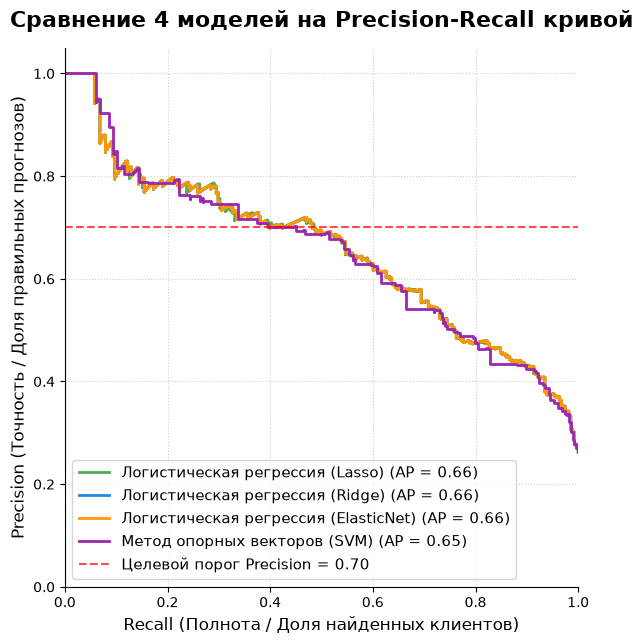

In [117]:
# 1. Собираем вероятности класса 1 со всех 4 моделей на тест-сете X_test
proba_lasso = search_lr_Lasso.best_estimator_.predict_proba(X_test)[:, 1]
proba_ridge = search_lr_Ridge.best_estimator_.predict_proba(X_test)[:, 1]
proba_elastic = search_lr_elasticnet.best_estimator_.predict_proba(X_test)[:, 1]
proba_svm = search_svm.best_estimator_.predict_proba(X_test)[:, 1]

# 2. Создаем одно общее полотно для графика
fig, ax = plt.subplots(figsize=(11, 7))

# 3. Добавляем каждую модель на график (задаем разные красивые цвета)
PrecisionRecallDisplay.from_predictions(
    y_test, proba_lasso,
    name="Логистическая регрессия (Lasso)", ax=ax, color='#4CAF50', linewidth=2
)

PrecisionRecallDisplay.from_predictions(
    y_test, proba_ridge,
    name="Логистическая регрессия (Ridge)", ax=ax, color='#1E88E5', linewidth=2
)

PrecisionRecallDisplay.from_predictions(
    y_test, proba_elastic,
    name="Логистическая регрессия (ElasticNet)", ax=ax, color='#FF9800', linewidth=2
)

PrecisionRecallDisplay.from_predictions(
    y_test, proba_svm,
    name="Метод опорных векторов (SVM)", ax=ax, color='#9C27B0', linewidth=2
)

# 4. Стилизация графика и добавление целевой линии по требованию преподавателя
ax.set_title("Сравнение 4 моделей на Precision-Recall кривой", fontsize=16, fontweight='bold', pad=15)
ax.set_xlabel("Recall (Полнота / Доля найденных клиентов)", fontsize=12)
ax.set_ylabel("Precision (Точность / Доля правильных прогнозов)", fontsize=12)

# Добавляем горизонтальную линию на уровне Precision = 0.70
ax.axhline(y=0.70, color='red', linestyle='--', alpha=0.7, linewidth=1.5, label='Целевой порог Precision = 0.70')

# Корректируем легенду и сетку
ax.legend(loc='lower left', fontsize=11)
ax.grid(True, linestyle=':', alpha=0.6)

# Ограничиваем оси для аккуратности
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])

# Убираем верхнюю и правую рамку (стиль seaborn/modern)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.show()

Так как веса фичей в линейных моделях отличаются незначительно, качество у них одинаковое, все 4 модели показывают почти одинаковую площадь под кривой AP, возьмем за baseline Lasso и проинтерпритируем важность разных фичей для предсказания оттока  

0.8367049620893786


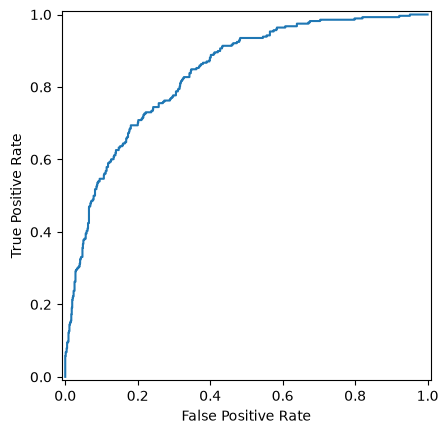

In [119]:
# Нарисуем Roc-кривую и посчитаем Roc-AUC!

fpr, tpr, thresholds = roc_curve(y_test, search_lr_Lasso.predict_proba(X_test)[:, 1])
print(auc(fpr, tpr))

roc_display = RocCurveDisplay(fpr=fpr, tpr=tpr).plot()

Площадь под ROC-кривой. Показывает общую способность модели разделять классы (вероятность того, что случайно выбранный положительный объект получит скор выше, чем случайно выбранный отрицательный). Значение 0.836 считается хорошим показателем разделяющей способности.

# VI. Интерпретация результатов¶



Итак, все наши модели показывают примерно одинаковое


При фиксированном Precision ≥ 70% текущие метрики говорят о следующем:
 - Каждый 7-й из 10 клиентов, которым модель предсказала отток, действительно собирается уйти (Precision = 70%). Деньги на удержание тратятся эффективно. Ложные срабатывания сведены к минимуму.
 - Однако мы спасаем только 42.8% уходящих (Recall = 0.428). Остальные 57.2% клиентов уходят незамеченными для модели, так как их скор не прошел установленный жесткий порог.
 - Потенциал модели (AUC = 0.837): Сама модель обучилась хорошо и качественно разделяет «уходящих» от «лояльных». Низкий Recall — это не проблема слабости алгоритма, это прямое следствие вашего жесткого бизнес-ограничения на Precision.

по фичам можно сказать следующее:

Топ-факторы, удерживающие клиентов (Самые сильные отрицательные веса)

Чем меньше (отрицательнее) коэффициент, тем ниже вероятность того, что клиент уйдет. 
 - Contract_Two year (-1.37) и Contract_One year (-0.70): Долгосрочные контракты - главный барьер для оттока. Клиенты с контрактом на 1 или 2 года уходят значительно реже тех, кто платит помесячно. 
 - PhoneService_Yes (-1.15): Наличие домашнего телефона прочно связывает клиента с компанией. 
 - tenure (-0.86): Срок жизни клиента критически важен. Чем дольше человек пользуется услугами компании, тем он лояльнее. 
 - Дополнительные услуги (TechSupport_Yes -0.55, OnlineSecurity_Yes -0.51): Техническая поддержка и цифровая безопасность работают как «якоря». Клиенты, подключившие эти опции, уходят неохотно.

Топ-факторы риска (Самые сильные положительные веса)

Чем выше коэффициент, тем сильнее этот признак провоцирует клиента расторгнуть контракт. 
 - MonthlyCharges (+0.95): Высокая стоимость - главный триггер ухода. Если ежемесячный чек растет, вероятность оттока увеличивается драматически.
 - PaperlessBilling_Yes (+0.33): Электронный счет часто коррелирует с оттоком. Возможно, такие клиенты более технологичны, легче сравнивают цены на рынке и быстрее переходят к конкурентам.
 - PaymentMethod_Electronic check (+0.31): Оплата электронным чеком (в отличие от автоплатежей) требует ручных действий каждый месяц. Это лишний раз заставляет клиента задумываться о расходах и триггерит желание отключиться.

Давайте применем метод permutation_importance и посмотрим важность признаком таким способом

Text(0.5, 1.0, 'Permutation Importance with Standard Deviation')

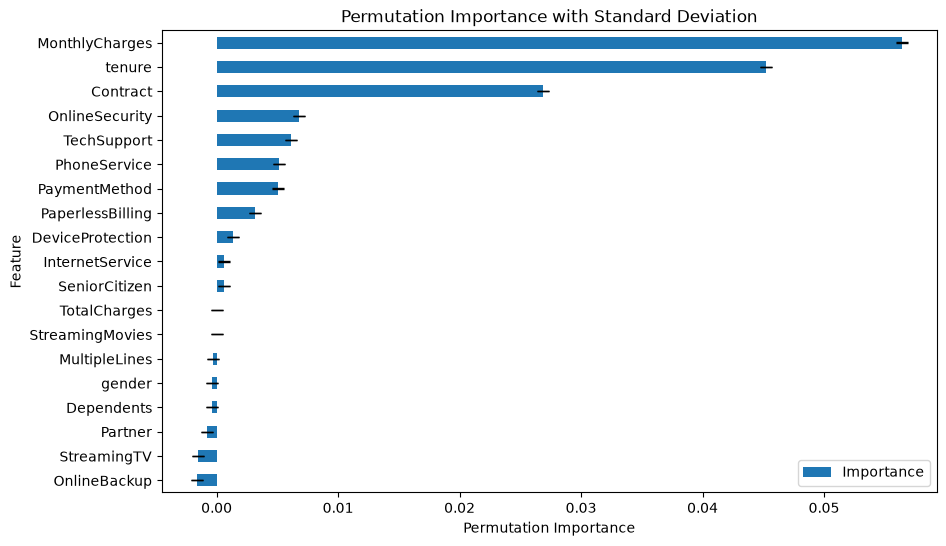

In [120]:
result = permutation_importance(search_lr_Lasso.best_estimator_, X_test, y_test, n_repeats=10, random_state=42)


feature_importance = pd.DataFrame({'Feature': X_test.columns,
                                   'Importance': result.importances_mean,
                                   'Standard Deviation': result.importances_std})
feature_importance = feature_importance.sort_values('Importance', ascending=True)


ax = feature_importance.plot(x='Feature', y='Importance', kind='barh', figsize=(10, 6), yerr='Standard Deviation', capsize=4)
ax.set_xlabel('Permutation Importance')
ax.set_title('Permutation Importance with Standard Deviation')

Три признака с огромным отрывом определяют качество прогноза. Без них модель полностью потеряет предсказательную силу:
1. MonthlyCharges (Ежемесячный платеж): Самый важный признак для модели. Стоимость услуг имеет решающее значение для клиентов.
2. tenure (Время жизни клиента): На втором месте по важности. Длительность отношений клиента с компанией критически важна для понимания лояльности.
3. Contract (Тип контракта): Замыкает тройку лидеров. Наличие долгосрочного договора - ключевой фактор, удерживающий людей.

Признаки средней важности

Эти факторы вносят стабильный, хотя и меньший вклад в предсказание оттока:
 - Сервисы безопасности и поддержки (OnlineSecurity, TechSupport) - наличие этих опций «привязывает» клиента.
 - Базовые и технические параметры (PhoneService, PaymentMethod, PaperlessBilling): Способ оплаты и наличие телефона важны для модели, их перемешивание заметно снижает метрики.


Бизнес-вывод для маркетинга:

Идеальный кандидат на уход выглядит так: «Новый клиент с высоким ежемесячным платежом (MonthlyCharges), без долгосрочного контракта (Month-to-month), который платит электронными чеками вручную и не пользуется техподдержкой».
Для удержания таких клиентов бизнесу нужно:


1. Переводить клиентов на годовые контракты: Давать скидки и бонусы за подписание контракта на 1–2 года, так как это сильнее всего снижает отток.
2. Продавать экосистему (Cross-sell): Активно предлагать пакеты с техподдержкой (TechSupport) и безопасностью (OnlineSecurity).
3. Работать с ценностью, а не только с ценой: Так как MonthlyCharges - главный драйвер ухода, нужно либо предлагать более дешевые тарифы тем, кто собирается уйти, либо наглядно обосновывать ценность дорогого тарифа.
4. Стимулировать автоплатежи: Переводить людей с электронных чеков на автоматическое списание по картам (Credit card имеет отрицательный вес -0.08, что удерживает клиентов).

Мы построили baseline модель и интерпритировали важность фичей для предсказания оттока, теперь можем улучшить модель предсказания, используя деревья и ансамбли 